# 05. Motor 1 — baseline estadístico de similitud del coseno

El Motor 1 responde una pregunta deliberadamente acotada: **entre
AGEBs que ya tienen estaciones, ¿la similitud del entorno permite
redescubrir las de mayor actividad observada media por estación?**
Es un baseline transparente: cada AGEB se representa en el espacio de
atributos del cuaderno 03 y se ordena por su similitud de coseno a un
centroide de referencia de alta actividad.

**Lo que este motor puede decir.** Si el baseline recupera las AGEBs
relevantes de cada pliegue, la estructura de similitud del entorno
contiene señal útil para priorizar territorio; si no, la tesis no
puede apoyarse en similitud ingenua.

**Lo que no puede decir.** La similitud no es demanda: el ranking
territorial del cierre es una **heurística de priorización**, no una
estimación de viajes ni de demanda latente. No usa coordenadas,
conteos de estaciones ni banderas Golden como insumo —estas últimas
están prohibidas porque su umbral P85 se calculó con todas las
estaciones, incluidas las de validación.

**La tarea común.** El cuaderno 04 alimenta a los motores 1, 2 y 3
**en paralelo**: los tres resuelven la misma tarea de despliegue
—un portafolio de $B$ sitios bajo reglas de red idénticas— con
métodos distintos, y ninguno lee las salidas de los otros. El
cierre de este cuaderno aporta la respuesta del Motor 1: un
portafolio de sitios por presupuesto, **sin cuotas por AGEB** —el
techo por análogos se retiró tras mostrarse peor que una densidad
constante (sección 7)—.

**Insumos.** Todo proviene de publicaciones verificadas byte a byte:
el contrato de atributos y el pipeline del cuaderno 03, el universo,
las particiones, el arnés y el contrato de despliegue —sitios,
celdas, reglas y métricas— del cuaderno 04, y el entorno de
estaciones del cuaderno 02.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display, Markdown, JSON

BASE = Path.cwd().resolve()
PROJECT = next(p / "4_proyecto" for p in [BASE, *BASE.parents] if (p / "4_proyecto/V3/data").is_dir())
V3_DIR = PROJECT / "V3"
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from V3.src.m1_analysis import (
    CONFIG, VARIANTS, PRIMARY_VARIANT, load_inputs, analyze)
from V3.src.m1_publication import stage_results

GREEN, GRAY, BLUE, RED, GOLD = "#004731", "#546E7A", "#0D47A1", "#B03A2E", "#B8860B"
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 11})
data = load_inputs(V3_DIR)
result = analyze(data)
report = result["report"]
display(pd.DataFrame([{
    "contract_id": report["contract_id"],
    "analysis_version": report["schema_version"],
    "feature_analysis_id": report["upstream"]["feature_analysis_id"],
    "eda_analysis_id": report["upstream"]["eda_analysis_id"],
    "validation_analysis_id": report["upstream"]["validation_analysis_id"],
    "primary_variant": report["primary_variant"],
}]))

,contract_id,analysis_version,feature_analysis_id,eda_analysis_id,validation_analysis_id,primary_variant
0,6e586b3d9a0bd8b844d9cf5bc714f0e583fc2a6936f8cd...,v3-motor1-3,7565adda3bc4eb91514247d2a1213f0b1c934821e762ac...,d77ab12f05e9025f438921b34e8688e1a7562826296427...,ed7bf47bafab10ca2b3144e9d38f1d06e5024ee9ba6af3...,m1_coseno_compuerta


## 1. Construcción local por pliegue

En cada pliegue, el motor ajusta un **pipeline fe03 nuevo**
(contrato de atributos, imputación por mediana, escalado y PCA al
objetivo de varianza declarado) usando **todas las AGEBs
proyectables fuera de `fit_exclusion_ids`** —incluidas candidatas
territoriales y cubiertas sin estación, que son filas de ajuste
legítimas porque no tienen etiqueta—. La prueba y su buffer nunca
entran al ajuste.

La **referencia de alta actividad** se construye solo con
`train_target`: las AGEBs de entrenamiento retenido con actividad
media por estación en el cuantil superior declarado, y su centroide
$\mu$ en el espacio PCA **del pliegue**. El número de componentes
`k_fold` puede variar entre pliegues porque el PCA se reajusta en
cada uno.

In [2]:
diag = result["fold_diagnostics"]
prim = diag.loc[diag.variant.eq(PRIMARY_VARIANT)]
display(prim[["fold_scheme", "fold", "k_fold", "n_reference",
             "n_over_p", "reference_threshold", "domain_threshold",
             "n_in_domain_test", "n_test", "covariance_estimator",
             "shrinkage", "condition_number",
             "condition_number_empirical", "empirical_status"]])

,fold_scheme,fold,k_fold,n_reference,n_over_p,reference_threshold,domain_threshold,n_in_domain_test,n_test,covariance_estimator,shrinkage,condition_number,condition_number_empirical,empirical_status
0,fold_groupkfold_ageb,0,8.0,29.0,3.625000,122.559201,4.855347,46.0,49,ledoit_wolf,0.348366,6.598674,34.117156,ok
1,fold_groupkfold_ageb,1,8.0,29.0,3.625000,119.787763,4.855347,47.0,49,ledoit_wolf,0.350906,6.188560,41.920425,ok
2,fold_groupkfold_ageb,2,8.0,29.0,3.625000,121.790365,4.855347,43.0,48,ledoit_wolf,0.472824,3.792566,32.364649,ok
3,fold_groupkfold_ageb,3,8.0,29.0,3.625000,125.124863,4.855347,39.0,48,ledoit_wolf,0.242461,9.179966,27.952740,ok
4,fold_groupkfold_ageb,4,8.0,29.0,3.625000,122.619612,4.855347,44.0,48,ledoit_wolf,0.335366,6.200406,27.038574,ok
5,fold_spatial_block,0,9.0,18.0,2.000000,82.031370,5.025601,52.0,55,ledoit_wolf,0.699436,2.261523,36.967875,ok
6,fold_spatial_block,1,9.0,23.0,2.555556,132.175148,5.025601,36.0,39,ledoit_wolf,0.396532,5.970887,53.360520,ok
7,fold_spatial_block,2,9.0,21.0,2.333333,132.025868,5.025601,42.0,47,ledoit_wolf,0.606082,2.974221,46.327299,ok
8,fold_spatial_block,3,9.0,21.0,2.333333,112.875394,5.025601,45.0,52,ledoit_wolf,0.381855,6.442887,54.938998,ok
9,fold_spatial_block,4,9.0,23.0,2.555556,92.674578,5.025601,43.0,49,ledoit_wolf,0.535908,3.236620,33.450146,ok


## 2. Coseno y compuerta de dominio

La similitud de coseno mide **dirección, no magnitud**: dos AGEBs con
perfil proporcional $(1,1)$ y $(10,10)$ tienen coseno 1 aunque sus
niveles difieran por un factor de diez —la variante euclidiana, que
sí distingue magnitudes, queda como comparador—. Una norma cero hace
indefinido el coseno y produce abstención, no un puntaje inventado.

La **compuerta de dominio** ajusta `fit_mahalanobis` sobre las
coordenadas PCA de la referencia del pliegue, con umbral
$\sqrt{\chi^2_{k_{fold}}(q)}$ y `df = k_fold`. Con referencias
pequeñas —el cuantil de referencia retiene apenas ~15% del
entrenamiento, y la razón $n/p \approx 3$— la covarianza muestral es
**inestable**: autovalores pequeños cercanos a cero inflan la
distancia en direcciones mal estimadas. Por eso la compuerta usa el
estimador **Ledoit-Wolf**, que encoge la covarianza muestral hacia
la diagonal escalada con un encogimiento estimado por los datos; la
tabla reporta por pliegue el encogimiento y el número de condición
junto al de la covarianza empírica (o el motivo de su rechazo).

**Umbral nominal.** Con encogimiento, las distancias de la referencia
ya no siguen exactamente una $\chi^2_{k}$: el cuantil es un corte
nominal coherente con el arnés, no una cobertura probabilística
exacta. Fuera de dominio significa extrapolación fuera del soporte,
no «mala ubicación». La variante `m1_coseno_compuerta_empirica`
conserva la compuerta empírica anterior como contraste explícito en
el backtest.

In [3]:
g = prim.loc[prim.fold_scheme.eq(CONFIG["primary_scheme"])].copy()
g["share_in_domain"] = g.n_in_domain_test / g.n_test
display(g[["fold", "k_fold", "n_reference", "n_over_p",
           "domain_threshold", "shrinkage", "condition_number",
           "condition_number_empirical", "empirical_status",
           "n_in_domain_test", "n_test", "share_in_domain"]])
display(Markdown(
    f"**Participación dentro de dominio (esquema primario):** "
    f"media {g.share_in_domain.mean():.2%}, "
    f"mínima {g.share_in_domain.min():.2%}."))
gate = report["deployment"]["gate"]
display(Markdown("**Compuerta de despliegue (referencia global)**"))
display(pd.Series(gate, name="valor").to_frame())

,fold,k_fold,n_reference,n_over_p,domain_threshold,shrinkage,condition_number,condition_number_empirical,empirical_status,n_in_domain_test,n_test,share_in_domain
5,0,9.0,18.0,2.000000,5.025601,0.699436,2.261523,36.967875,ok,52.0,55,0.945455
6,1,9.0,23.0,2.555556,5.025601,0.396532,5.970887,53.360520,ok,36.0,39,0.923077
7,2,9.0,21.0,2.333333,5.025601,0.606082,2.974221,46.327299,ok,42.0,47,0.893617
8,3,9.0,21.0,2.333333,5.025601,0.381855,6.442887,54.938998,ok,45.0,52,0.865385
9,4,9.0,23.0,2.555556,5.025601,0.535908,3.236620,33.450146,ok,43.0,49,0.877551


**Participación dentro de dominio (esquema primario):** media 90.10%, mínima 86.54%.

**Compuerta de despliegue (referencia global)**

,valor
threshold,4.855347
min_eigenvalue,0.530375
condition_number,6.028456
n_reference,37.0
k_dims,8.0
covariance_rank,8.0
quantile,0.9973
df,8.0
chi2_ppf,23.574394
shrinkage,0.339262


## 3. Backtest espacial contra el arnés del 04

Todas las variantes corren sobre **ambos esquemas** del arnés. El
esquema por AGEB es la **referencia optimista** (no aísla vecinos);
el veredicto se lee en `fold_spatial_block` con buffer de 500 m. Los
comparadores son deliberados: `m1_coseno_compuerta_empirica` (la
compuerta anterior con covarianza muestral —mide si Ledoit-Wolf
cambia `decision_coverage` y las métricas, sin afirmar mejora si no
la hay—), `m1_coseno` sin compuerta (¿la abstención cuesta o
protege?), `m1_euclidiana` (¿importa la magnitud?), `heur_metro`
(heurística transparente de distancia al METRO/MB, sin ajuste) y
`control_aleatorio` (plomería: debe rondar la tasa base).

Las victorias pliegue a pliegue contra cada comparador se cuentan de
forma **descriptiva** —cinco pliegues no sustentan inferencia
estadística—. Si el primario no supera a `heur_metro` o al control
aleatorio, el cuaderno lo dice explícitamente.

metric                                             precision@10  recall@10  \
variant                      fold_scheme                                     
control_aleatorio            fold_groupkfold_ageb          0.22   0.307857   
                             fold_spatial_block            0.32   0.250978   
heur_metro                   fold_groupkfold_ageb          0.26   0.349286   
                             fold_spatial_block            0.30   0.326619   
m1_coseno                    fold_groupkfold_ageb          0.40   0.536429   
                             fold_spatial_block            0.38   0.318556   
m1_coseno_compuerta          fold_groupkfold_ageb          0.40   0.536429   
                             fold_spatial_block            0.38   0.318556   
m1_coseno_compuerta_empirica fold_groupkfold_ageb          0.38   0.511429   
                             fold_spatial_block            0.34   0.342004   
m1_euclidiana                fold_groupkfold_ageb          0.28   0.396429   
                             fold_spatial_block            0.18   0.210155   

metric                                              ndcg@10  ndcg_cond@10  \
variant                      fold_scheme                                    
control_aleatorio            fold_groupkfold_ageb  0.535693      0.535693   
                             fold_spatial_block    0.540956      0.540956   
heur_metro                   fold_groupkfold_ageb  0.643797      0.643797   
                             fold_spatial_block    0.673633      0.673633   
m1_coseno                    fold_groupkfold_ageb  0.755134      0.755134   
                             fold_spatial_block    0.673203      0.673203   
m1_coseno_compuerta          fold_groupkfold_ageb  0.755134      0.777579   
                             fold_spatial_block    0.673203      0.709360   
m1_coseno_compuerta_empirica fold_groupkfold_ageb  0.740047      0.780983   
                             fold_spatial_block    0.679110      0.762104   
m1_euclidiana                fold_groupkfold_ageb  0.679581      0.679581   
                             fold_spatial_block    0.574281      0.574281   

metric                                             precision_cond@10  \
variant                      fold_scheme                               
control_aleatorio            fold_groupkfold_ageb               0.22   
                             fold_spatial_block                 0.32   
heur_metro                   fold_groupkfold_ageb               0.26   
                             fold_spatial_block                 0.30   
m1_coseno                    fold_groupkfold_ageb               0.40   
                             fold_spatial_block                 0.38   
m1_coseno_compuerta          fold_groupkfold_ageb               0.40   
                             fold_spatial_block                 0.38   
m1_coseno_compuerta_empirica fold_groupkfold_ageb               0.38   
                             fold_spatial_block                 0.34   
m1_euclidiana                fold_groupkfold_ageb               0.28   
                             fold_spatial_block                 0.18   

metric                                             decision_coverage  \
variant                      fold_scheme                               
control_aleatorio            fold_groupkfold_ageb           1.000000   
                             fold_spatial_block             1.000000   
heur_metro                   fold_groupkfold_ageb           1.000000   
                             fold_spatial_block             1.000000   
m1_coseno                    fold_groupkfold_ageb           1.000000   
                             fold_spatial_block             1.000000   
m1_coseno_compuerta          fold_groupkfold_ageb           0.904592   
                             fold_spatial_block             0.901017   
m1_coseno_compuerta_empirica fold_groupkfold_ageb           0.747364   
                           

/var/folders/xy/k1hx31l15bq5npxk8h1gcpwc0000gn/T/ipykernel_86098/837343103.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data_plot, labels=[v.replace("m1_", "") for v in order],
/var/folders/xy/k1hx31l15bq5npxk8h1gcpwc0000gn/T/ipykernel_86098/837343103.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data_plot, labels=[v.replace("m1_", "") for v in order],


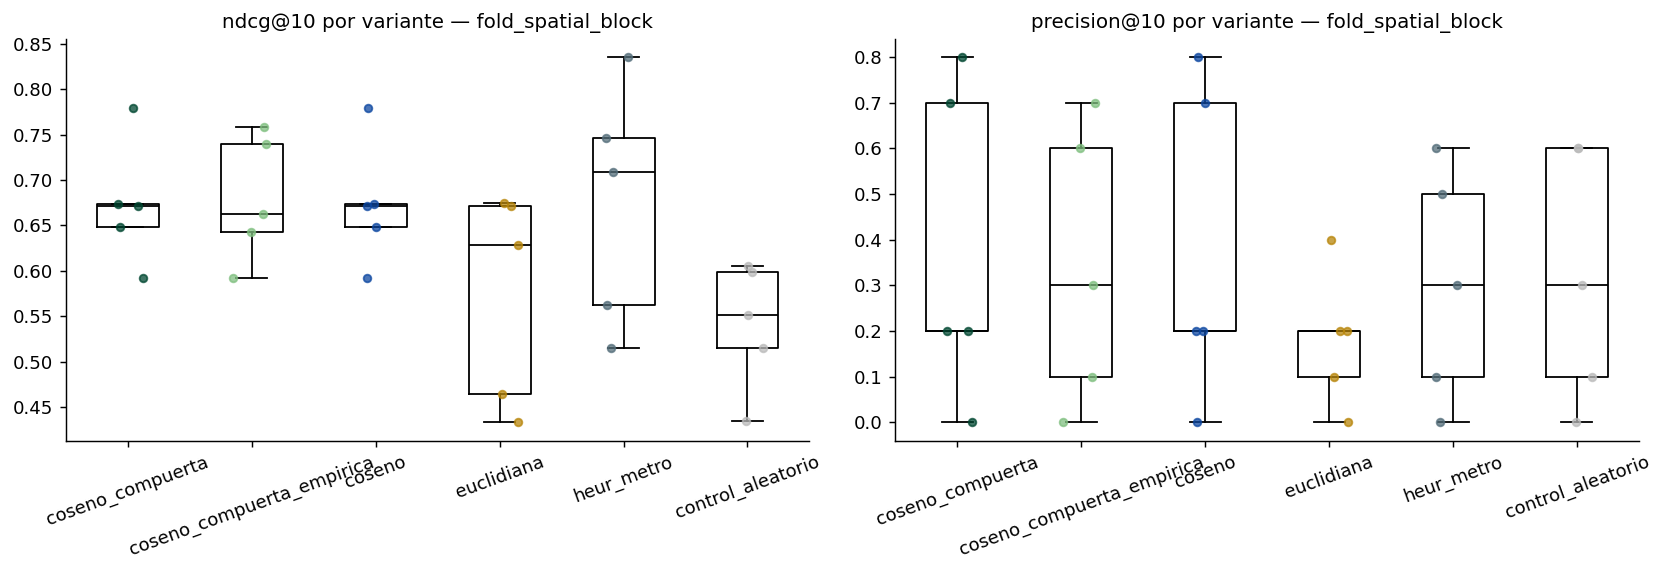

**Victorias del primario por pliegue** (esquema primario, descriptivo)

,metric,comparator,wins,ties,losses
0,ndcg@10,m1_coseno_compuerta_empirica,3,1,1
1,ndcg@10,m1_coseno,0,5,0
2,ndcg@10,m1_euclidiana,3,0,2
3,ndcg@10,heur_metro,3,0,2
4,ndcg@10,control_aleatorio,5,0,0
5,precision@10,m1_coseno_compuerta_empirica,3,1,1
6,precision@10,m1_coseno,0,5,0
7,precision@10,m1_euclidiana,3,2,0
8,precision@10,heur_metro,3,1,1
9,precision@10,control_aleatorio,3,1,1


In [4]:
summ = result["backtest_summary"]
key_metrics = ["precision@10", "recall@10", "ndcg@10",
               "ndcg_cond@10", "precision_cond@10",
               "decision_coverage",
               "relevant_abstained", "n_relevant"]
piv = (summ.loc[summ.metric.isin(key_metrics)]
       .pivot_table(index=["variant", "fold_scheme"],
                    columns="metric", values="mean"))
display(piv[[c for c in key_metrics if c in piv.columns]])
detail = result["backtest_detail"]
nan_recall = detail.loc[detail["recall@10"].isna(),
                        ["variant", "fold_scheme", "fold", "n_relevant"]]
if len(nan_recall):
    display(Markdown("**Pliegues sin relevantes** — recall `NaN` "
                     "reportado explícitamente:"))
    display(nan_recall)
prim_scheme = CONFIG["primary_scheme"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
palette = {"m1_coseno_compuerta": GREEN,
           "m1_coseno_compuerta_empirica": "#80C080",
           "m1_coseno": BLUE, "m1_euclidiana": GOLD,
           "heur_metro": GRAY, "control_aleatorio": "#BBBBBB"}
for ax, metric in zip(axes, ["ndcg@10", "precision@10"]):
    sub = detail.loc[detail.fold_scheme.eq(prim_scheme)]
    order = VARIANTS
    data_plot = [sub.loc[sub.variant.eq(v), metric].to_numpy()
                 for v in order]
    ax.boxplot(data_plot, labels=[v.replace("m1_", "") for v in order],
               showfliers=False, medianprops={"color": "black"})
    rng_plot = np.random.default_rng(7)
    for i, vals in enumerate(data_plot):
        ax.scatter(rng_plot.uniform(i + 0.85, i + 1.15, len(vals)),
                   vals, s=18, alpha=0.75,
                   color=palette[order[i]], zorder=3)
    ax.set_title(f"{metric} por variante — {prim_scheme}")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()
display(Markdown("**Victorias del primario por pliegue** "
                 "(esquema primario, descriptivo)"))
display(result["win_counts"])

## 4. Sensibilidad de la configuración

Un factor a la vez sobre la variante y el esquema primarios:
objetivo de varianza del PCA, cuantil de referencia y cuantil de
dominio. La tabla reporta la media por pliegue de las métricas del
arnés bajo cada valor alternativo.

,parameter,value,k_fold_mean,mean_decision_coverage,mean_relevant_abstained,mean_effective_k@10,mean_precision@10,mean_recall@10,mean_ndcg@10,mean_ndcg_cond@10,...,mean_recall@20,mean_ndcg@20,mean_ndcg_cond@20,mean_precision_cond@20,mean_effective_k@50,mean_precision@50,mean_recall@50,mean_ndcg@50,mean_ndcg_cond@50,mean_precision_cond@50
0,variance_target,0.70,6.8,0.911379,0.8,10.0,0.38,0.363057,0.682675,0.701039,...,0.480263,0.738765,0.758135,0.29,47.0,0.212410,0.913563,0.827971,0.874213,0.223583
1,variance_target,0.90,11.0,0.883025,1.2,10.0,0.38,0.318556,0.658364,0.693596,...,0.508097,0.720038,0.756307,0.30,47.0,0.208328,0.903036,0.796202,0.869953,0.228729
2,reference_quantile,0.75,9.0,0.922338,1.0,10.0,0.36,0.290722,0.656645,0.686826,...,0.512955,0.726165,0.757597,0.31,47.0,0.212328,0.910729,0.815041,0.872170,0.225835
3,reference_quantile,0.90,9.0,0.876764,0.8,10.0,0.36,0.310864,0.669995,0.692175,...,0.485931,0.727875,0.751746,0.29,47.0,0.215364,0.831781,0.808242,0.872556,0.230017
4,domain_quantile,0.95,9.0,0.738724,2.4,10.0,0.38,0.318556,0.673203,0.729538,...,0.523482,0.735728,0.799734,0.32,47.0,0.187037,0.766599,0.735700,0.884608,0.229168
5,domain_quantile,0.99,9.0,0.850611,1.8,10.0,0.38,0.318556,0.673203,0.721669,...,0.515789,0.737827,0.788248,0.31,47.0,0.199119,0.792510,0.790275,0.887410,0.218750


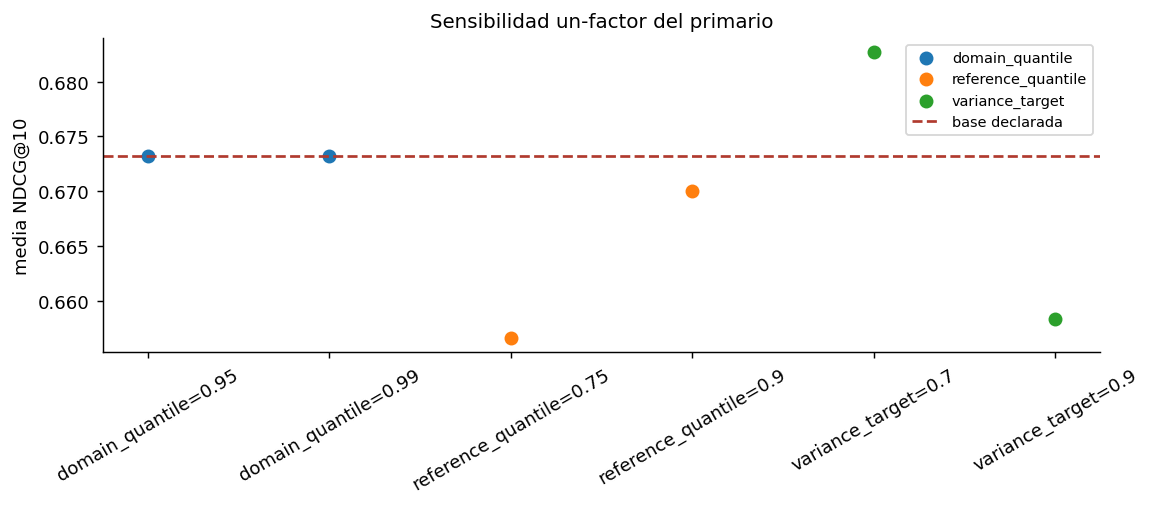

In [5]:
sens = result["sensitivity"]
display(sens)
fig, ax = plt.subplots(figsize=(9, 4))
for param, sub in sens.groupby("parameter"):
    ax.scatter([f"{param}={v}" for v in sub.value],
               sub["mean_ndcg@10"], s=45, label=param)
base = detail.loc[detail.variant.eq(PRIMARY_VARIANT)
                & detail.fold_scheme.eq(prim_scheme), "ndcg@10"].mean()
ax.axhline(base, color=RED, ls="--", label="base declarada")
ax.set(ylabel="media NDCG@10", title="Sensibilidad un-factor del primario")
ax.tick_params(axis="x", rotation=30)
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Ranking territorial de despliegue

Para el despliegue el espacio es **exactamente el publicado por el
cuaderno 03**: el pipeline se ajusta sobre todas las AGEBs
proyectables y el cuaderno verifica que su transformación reproduce
los scores publicados y coincide con el pipeline cargado por el
cargador verificado —si difiriera, el cuaderno fallaría—.

La referencia global son las AGEBs evaluables con actividad media en
el cuantil superior declarado; la tabla cruzada contra el Golden-03
muestra cuánta coincidencia hay entre ambas nociones de «alta
actividad». La compuerta m1 usa la covarianza de **esa** referencia,
no la Golden. `attractiveness = max(cos, 0)` dentro de dominio y 0
fuera: es el insumo declarado del Motor 3, no una probabilidad.

,valor
space_reproduction,deployment space = published 03 space (atol 1e...
reference_quantile,0.85
reference_threshold,122.381416
n_reference,37
candidates,2064
candidates_in_domain_m1,1076
candidates_out_domain_m1,988
top50_in_domain_frontier,13
attractiveness_definition,"max(cos_score, 0) if in_domain else 0; Motor 3..."


**Referencia m1 vs Golden-03** (filas: pertenencia a la referencia m1)

,golden_03,non_golden
below_reference,26,179
in_reference,35,2


**Compuerta m1 vs estatus publicado del 04**

,in_domain,out_of_domain
in_domain,764,312
out_of_domain,5,983


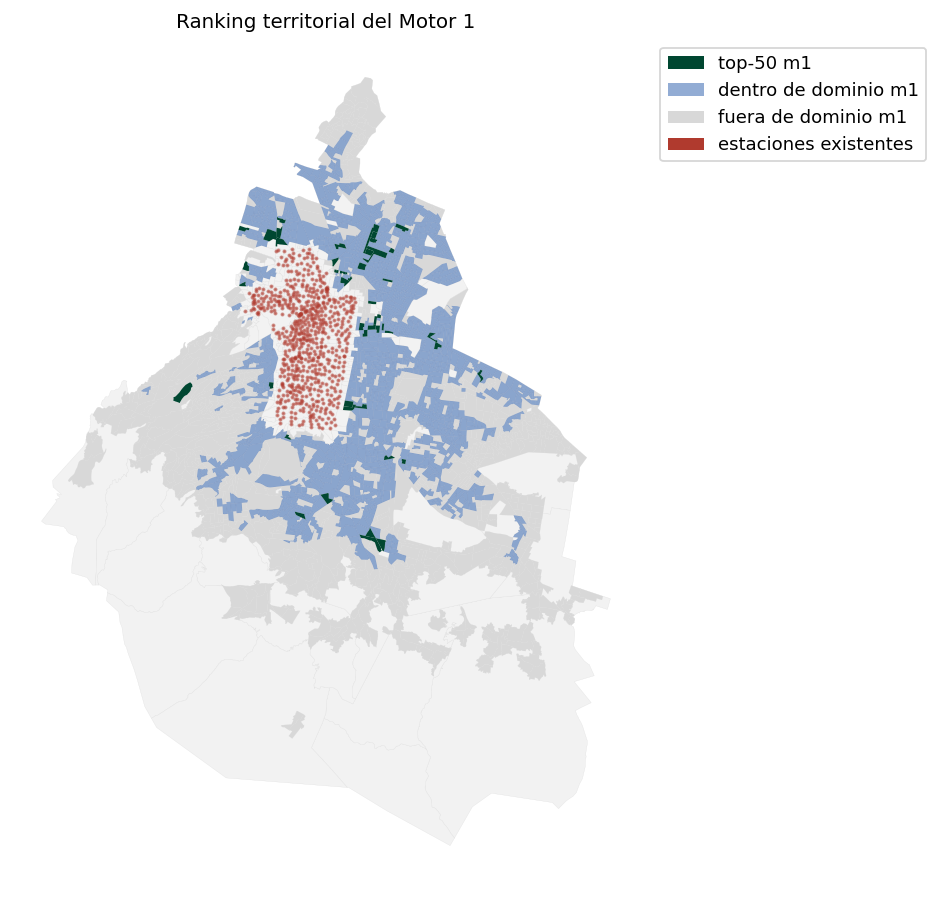

,cvegeo,nom_mun,cos_score,mahalanobis_m1,domain_status_m1,domain_status_04,rank_m1,rank_sin_compuerta,attractiveness,dist_red_m,frontera
37,0900200010472,Azcapotzalco,0.874336,2.260278,in_domain,in_domain,1,1,0.874336,255.934359,True
36,0900200010468,Azcapotzalco,0.861104,2.291884,in_domain,in_domain,2,2,0.861104,877.719750,True
2044,0901700011327,Venustiano Carranza,0.852769,2.217025,in_domain,in_domain,3,3,0.852769,1085.997321,False
1824,0901500010061,Cuauhtémoc,0.846370,1.971357,in_domain,in_domain,4,4,0.846370,718.148925,True
1965,0901700010507,Venustiano Carranza,0.842128,2.386964,in_domain,in_domain,5,5,0.842128,1024.588853,False
724,0900700010924,Iztapalapa,0.835536,2.276781,in_domain,in_domain,6,6,0.835536,1362.857408,False
1840,0901500010273,Cuauhtémoc,0.834907,2.983413,in_domain,in_domain,7,7,0.834907,1222.335181,False
1837,090150001024A,Cuauhtémoc,0.812524,2.872282,in_domain,in_domain,8,8,0.812524,747.071833,True
1836,0901500010235,Cuauhtémoc,0.803639,2.510152,in_domain,in_domain,9,9,0.803639,615.233823,True
714,0900700010801,Iztapalapa,0.767992,2.621212,in_domain,in_domain,10,10,0.767992,509.777745,True


In [6]:
dep = report["deployment"]
display(pd.Series({k: v for k, v in dep.items()
                   if not isinstance(v, (dict, list))},
                  name="valor").to_frame())
display(Markdown("**Referencia m1 vs Golden-03** "
                 "(filas: pertenencia a la referencia m1)"))
display(pd.DataFrame(dep["reference_vs_golden03"]))
display(Markdown("**Compuerta m1 vs estatus publicado del 04**"))
display(pd.DataFrame(dep["m1_vs_04_status"]))
ranking = result["ranking"]
universe = data["frames"]["universe"]
stations = data["frames"]["station_env"]
top50 = result["top50"]
fig, ax = plt.subplots(figsize=(9, 7))
universe.plot(ax=ax, color="#F2F2F2", edgecolor="#DDDDDD",
              linewidth=0.15)
ranking.loc[ranking.domain_status_m1.eq("out_of_domain")].plot(
    ax=ax, color="#D8D8D8", edgecolor="none")
in_dom = ranking.loc[ranking.domain_status_m1.eq("in_domain")]
in_dom.loc[~in_dom.index.isin(top50.index)].plot(
    ax=ax, color=BLUE, alpha=0.45, edgecolor="none")
top50.plot(ax=ax, color=GREEN, edgecolor="none")
stations.plot(ax=ax, color=RED, markersize=1.5, alpha=0.5)
ax.legend(handles=[
    Patch(facecolor=GREEN, label="top-50 m1"),
    Patch(facecolor=BLUE, alpha=0.45, label="dentro de dominio m1"),
    Patch(facecolor="#D8D8D8", label="fuera de dominio m1"),
    Patch(facecolor=RED, label="estaciones existentes")],
    loc="upper left", bbox_to_anchor=(1.02, 1))
ax.set_axis_off(); ax.set_title("Ranking territorial del Motor 1")
plt.tight_layout(); plt.show()
cols = ["cvegeo", "nom_mun", "cos_score", "mahalanobis_m1",
        "domain_status_m1", "domain_status_04", "rank_m1",
        "rank_sin_compuerta", "attractiveness", "dist_red_m",
        "frontera"]
display(top50.head(20)[cols])

## 6. Sesgo y conectividad

La similitud del entorno puede estar **replicando contextos
afluentes**: las correlaciones de rango entre el puntaje de coseno y
los atributos socioeconómicos se reportan abajo, junto a la media de
esos atributos en el top-50 dentro de dominio frente a todas las
candidatas. La renta no se observa directamente.

La conectividad es **descriptor, no componente del puntaje**:
`dist_red_m` mide la distancia del polígono al punto de estación más
cercano y `frontera` marca candidatas dentro del umbral declarado.
Una parte del top-50 puede quedar lejos de la red existente —es el
motivo por el que el Motor 3 optimiza colocación y conectividad de
forma explícita en lugar de heredar el orden del baseline—.

In [7]:
display(result["bias"])
conn = report["connectivity"]
display(pd.Series(conn, name="valor").to_frame())
frontier = int(top50.frontera.sum())
display(Markdown(
    f"**Frontera de red.** {frontier} de las "
    f"{len(top50)} candidatas del top-50 dentro de dominio están a "
    f"{int(conn['frontier_m'])} m o menos de una estación existente; "
    f"mediana de distancia a la red: top-50 "
    f"{conn['median_dist_red_top50']:.0f} m vs. todas las candidatas "
    f"{conn['median_dist_red_all']:.0f} m."))

,feature,spearman_cos,mean_top50_in_domain,mean_all_candidates
0,grado_escolar_prom,0.721341,13.003600,11.355838
1,pct_viviendas_auto,0.538402,0.542220,0.462549
2,pct_viviendas_internet,0.668142,0.839702,0.735899
3,densidad_pob_km2,-0.154191,15794.815755,17087.456327


,valor
frontier_m,1000
median_dist_red_top50,2012.923141
median_dist_red_all,6266.058039
note,connectivity is descriptive in the territorial...


**Frontera de red.** 13 de las 50 candidatas del top-50 dentro de dominio están a 1000 m o menos de una estación existente; mediana de distancia a la red: top-50 2013 m vs. todas las candidatas 6266 m.

## 7. Portafolio del Motor 1 y remoción del techo por análogos

El portafolio usa el `greedy_coverage` del contrato 04 con puntaje
de sitio = atractividad de su AGEB anfitriona, bajo las reglas de
red idénticas para los tres motores, **sin techo por AGEB**: la
cantidad de estaciones que recibe cada AGEB es ahora únicamente el
resultado de la cobertura con rendimientos decrecientes.

### Remoción del techo por análogos

En la publicación anterior (`v3-motor1-2`) cada AGEB recibía un
*techo teórico*: la mediana de densidad histórica (estaciones/km²)
de sus 5 análogas de referencia por coseno, multiplicada por su
área. El backtest del techo mostró que **reproducía la densidad
histórica de planeación, no demanda**, y que **perdía contra una
densidad constante** —la mediana de densidad del pliegue— tanto en
MAE como en Spearman. Por eso se retiró del despliegue: imponerlo
heredaba a la cartera un patrón histórico de inversión que no es
evidencia sobre el objetivo.

El backtest se **conserva** a continuación solo como evidencia de
esa decisión: compara, dentro del mismo protocolo de pliegues, la
densidad por análogos contra la densidad constante mediana. Los
campos de techo (`ceiling`, `hits_ceiling_*`, `allocated_B*`) ya no
existen en las salidas publicadas. La tabla de contraste compara el
portafolio $B=30$ de esta publicación con el publicado anteriormente.

,valor
mae_analog,1.677686
spearman_analog,0.274434
mae_naive,1.256198
spearman_naive,0.307494
n_rows,242
role,historical diagnostic only — evidence supporti...


**Corrida previa (v3-motor1-2, referencia)**

,valor
mae_analog,1.669
spearman_analog,0.355
mae_naive,1.227
spearman_naive,0.295
source,v3-motor1-2 report


**Cambio del portafolio por la remoción del techo** (presupuesto primario B=30)

,previo (con techos),actual (sin techos)
new_pop,153809.570982,202337.349801
n_agebs,21,21
stations_per_ageb,"{'1': 14, '2': 5, '3+': 2}","{'1': 15, '2': 5, '3+': 1}"


,delta
delta_new_pop,48527.778819
delta_n_agebs,0.000000


**Métricas de portafolio por presupuesto** (contrato común)

,stop_reason,n_selected,new_pop,new_pop_share,redundancy,n_agebs,stations_per_ageb,max_hops_network,median_hops_golden,max_hops_golden,mean_dist_to_network_m,mean_grado_escolar_prom_selected,mean_grado_escolar_prom_all_sites,mean_pct_viviendas_auto_selected,mean_pct_viviendas_auto_all_sites,out_of_domain_04_share
15,budget,15,113528.207285,0.014248,0.6358,10,"{'1': 8, '2': 1, '3+': 1}",6,7.0,11,821.799667,13.188,12.234022,0.590887,0.521034,0.533333
30,budget,30,202337.349801,0.025393,0.625619,21,"{'1': 15, '2': 5, '3+': 1}",14,9.5,19,1262.31396,13.024,12.234022,0.589755,0.521034,0.3
50,budget,50,300803.122124,0.037751,0.643574,33,"{'1': 20, '2': 11, '3+': 2}",21,14.5,26,1552.939226,13.2718,12.234022,0.635619,0.521034,0.26


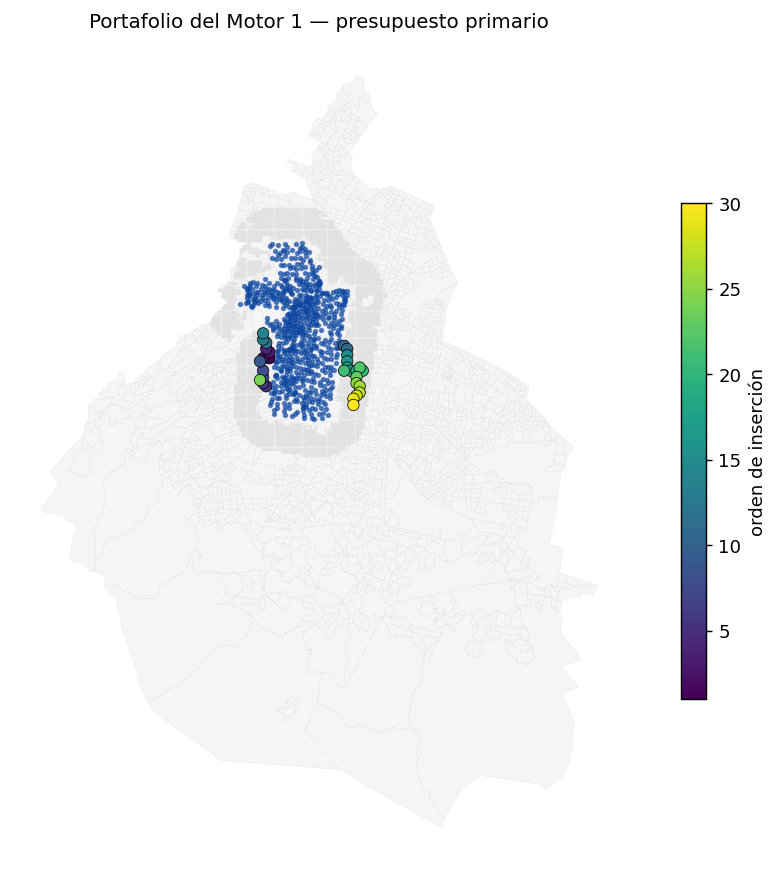

**Estaciones por AGEB** (presupuesto primario)

,n_agebs
count,
1,15
2,5
5,1


In [8]:
cb = report["ceiling_backtest"]
display(pd.Series({k: v for k, v in cb.items() if k != "previous_publication"},
                  name="valor").to_frame())
display(Markdown("**Corrida previa (v3-motor1-2, referencia)**"))
display(pd.Series(cb["previous_publication"], name="valor").to_frame())
rem = report["portafolio"]["techo_removido"]
display(Markdown("**Cambio del portafolio por la remoción del techo** "
                 "(presupuesto primario B=30)"))
display(pd.DataFrame({"previo (con techos)": rem["previous_B30"],
                      "actual (sin techos)": rem["current_B30"]}))
display(pd.Series({"delta_new_pop": rem["delta_B30_new_pop"],
                   "delta_n_agebs": rem["delta_B30_n_agebs"]},
                  name="delta").to_frame())
display(Markdown("**Métricas de portafolio por presupuesto** "
                 "(contrato común)"))
metrics_long = pd.DataFrame(
    report["portafolio"]["por_presupuesto"]).T
display(metrics_long)
port = result["portafolios"]
prim = port.loc[port.budget.eq(
    report["portafolio"]["budget_grid"][1])]
sites = result["sites"]
stations = data["frames"]["station_env"].to_crs(
    CONFIG["metric_crs"])
universe_g = data["frames"]["universe"].to_crs(
    CONFIG["metric_crs"])
fig, ax = plt.subplots(figsize=(9, 7))
universe_g.plot(ax=ax, color="#F5F5F5", edgecolor="#DDDDDD",
                linewidth=0.15)
sites.plot(ax=ax, color="#DDDDDD", markersize=1.5, alpha=0.5)
stations.plot(ax=ax, color=BLUE, markersize=4, alpha=0.6)
prim.plot(ax=ax, column="order", cmap="viridis", markersize=40,
          edgecolor="black", linewidth=0.4, legend=True,
          legend_kwds={"label": "orden de inserción",
                       "shrink": 0.6})
ax.set_axis_off()
ax.set_title("Portafolio del Motor 1 — presupuesto primario")
plt.tight_layout(); plt.show()
display(Markdown("**Estaciones por AGEB** (presupuesto primario)"))
display(prim.cvegeo.value_counts().value_counts().sort_index()
        .rename("n_agebs").to_frame())

## 8. Límites y publicación

El Motor 1 es un **baseline de similitud**, no un modelo de demanda:
sus métricas miden redescubrimiento de actividad observada entre
AGEBs servidas, su ranking territorial ordena candidatas por
parecido a un centroide de referencia, y ni la compuerta Ledoit-Wolf
—cuyo umbral χ² es nominal bajo encogimiento— ni la abstención
convierten a `attractiveness` en probabilidad de éxito. El techo por
análogos quedó fuera del despliegue por evidencia (perdía contra una
densidad constante); su backtest se conserva solo como diagnóstico
histórico. El portafolio usa las reglas comunes del contrato 04 sin
cuotas por AGEB y su factibilidad queda verificada por `is_feasible`;
la atractividad que puntúa sitios hereda el posible sesgo de
afluencia del baseline —el coseno sigue correlacionado con
escolaridad, internet y auto, y la similitud no es causalidad ni
demanda.

Se publican: el detalle y resumen del backtest por variante y
esquema, la tabla de decisiones, los diagnósticos por pliegue
(incluidos encogimiento y números de condición de la compuerta), la
sensibilidad, el ranking georreferenciado de candidatas, la tabla de
referencia, los portafolios por presupuesto, el backtest del techo
(evidencia de su remoción) y el paquete serializado del pipeline de
despliegue con su compuerta.

In [9]:
display(pd.DataFrame({"pending_validation":
                      report["pending_validation"]}))
report_path = stage_results(V3_DIR, data, result)
display(Markdown("**Cierre.** Baseline del Motor 1 publicado con "
                 "verificación de integridad: ranking territorial "
                 "y portafolio de sitios bajo el contrato común."))
display(JSON({"m1_report_path": report_path.relative_to(V3_DIR).as_posix()}))

,pending_validation
0,Sensitivity of deployment ranking to domain/re...


**Cierre.** Baseline del Motor 1 publicado con verificación de integridad: ranking territorial y portafolio de sitios bajo el contrato común.

<IPython.core.display.JSON object>